# Wang et al. 2019 — Glioblastoma (Brain) · 02 Manifold

Score the three embryonic modules → read geography (smoothed spatial correlations) to decide **topology from the embedding**, not a metric → fit scFates `curve` (non-branching) → derive the root from the developmental signature order → pseudotime → verify fold-free continuity on an **independent** diffusion embedding.

Geography here also front-loads the Gate-2 read: Gast/pSom co-vary and both oppose Crest -> a single collapsed axis (**non-branching**), so a `curve` is the correct object and Gate 3 will be NA.

In [1]:
import os, sys, glob, io, contextlib, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path
from scipy.stats import spearmanr
sc.settings.verbosity = 1; SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
os.makedirs(pth_fig, exist_ok=True)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'processed.h5ad'))
print('malignant manifold:', adata.shape[0], 'cells')
# UMAP aspect ratio: an elongated (near-1D) cloud is the signature of a linear compartment
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
from numpy.linalg import svd; _,ss,_ = svd(c, full_matrices=False)
print(f'UMAP aspect ratio (major/minor std): {ss[0]/ss[1]:.2f}')

malignant manifold: 9632 cells
UMAP aspect ratio (major/minor std): 1.48


In [4]:
# score the three embryonic modules with the union control pool (score_genes)
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src, lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=lab, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
# graph-smooth scores for a geography read robust to per-cell dropout noise (3 knn-averaging passes)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
for j, lab in enumerate(['Gast','pSom','Crest']): adata.obs[lab+'_sm'] = S[:,j]

Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 100/104 genes present


In [5]:
# TOPOLOGY from geography: co-varying Gast/pSom + inverse Crest = one collapsed axis (non-branching)
print('smoothed spatial correlations (geography):')
for a, b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.3f}')
adata.obs['cyc_score'] = adata.obs[['S_score','G2M_score']].max(axis=1)
print('\nproliferation orthogonality (cycling score vs modules):')
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  cyc_score vs {m}: r = {np.corrcoef(adata.obs.cyc_score, adata.obs[m])[0,1]:+.3f}')
print('\nper-state smoothed developmental means:')
print(adata.obs.groupby('celltype', observed=True)[['Gast_sm','pSom_sm','Crest_sm']].mean().round(4).to_string())
print('\nGast/pSom co-vary (r>0) and both oppose Crest; proliferation is orthogonal (|r|<0.15)')
print('-> single collapsed axis, NON-BRANCHING; keep the whole manifold (no cycling confound to scope out).')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = +0.163
  Crest_sm vs Gast_sm: r = -0.492
  Crest_sm vs pSom_sm: r = -0.869

proliferation orthogonality (cycling score vs modules):
  cyc_score vs Gast_sm: r = -0.047
  cyc_score vs pSom_sm: r = +0.115
  cyc_score vs Crest_sm: r = -0.120

per-state smoothed developmental means:
          Gast_sm  pSom_sm  Crest_sm
celltype                            
AC-like   -0.0043   0.0051   -0.0039
NPC-like  -0.0033   0.0175   -0.0148
OPC-like  -0.0023   0.0118   -0.0095

Gast/pSom co-vary (r>0) and both oppose Crest; proliferation is orthogonal (|r|<0.15)
-> single collapsed axis, NON-BRANCHING; keep the whole manifold (no cycling confound to scope out).


In [6]:
# fold/branch diagnostic on the fitted principal graph (topology measured off the graph, cross-checked to geography)
def fold_diag(ad):
    B = np.asarray(ad.uns['graph']['B']); F = ad.uns['graph']['F'].T
    G = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
    ii, jj = np.where(np.triu(B>0)); med = np.median(np.sqrt(((F[ii]-F[jj])**2).sum(1)))
    dmin = np.inf
    for a in range(F.shape[0]):
        for b in range(a+1, F.shape[0]):
            if G[a,b] >= 3: dmin = min(dmin, np.sqrt(((F[a]-F[b])**2).sum()))
    tips = int(((B>0).sum(0)==1).sum()); forks = int(((B>0).sum(0)>=3).sum())
    return dmin/med, tips, forks
# a PPT tree overfits spurious forks that SCALE with node count (tree-on-a-strip); geography already
# rules out a real bifurcation (Gast/pSom co-vary, not anti-correlate), so we fit a curve.
print('PPT-tree fork probe (spurious forks scale with Nodes -> not a real bifurcation):')
for N in [15, 20, 30]:
    with contextlib.redirect_stdout(io.StringIO()):
        scf.tl.tree(adata, method='ppt', Nodes=N, ppt_lambda=50, ppt_sigma=0.5,
                    use_rep='X_umap', seed=SEED, plot=False)
    B = np.asarray(adata.uns['graph']['B']); print(f'  Nodes={N}: forks={int(((B>0).sum(0)>=3).sum())}')

PPT-tree fork probe (spurious forks scale with Nodes -> not a real bifurcation):
  Nodes=15: forks=3
  Nodes=20: forks=1
  Nodes=30: forks=5


In [7]:
# fit the non-branching curve (ElPiGraph) on the UMAP embedding
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100.0, seed=SEED, plot=False)
sa, tips, forks = fold_diag(adata)
print(f'curve: {tips} tips, {forks} forks | fold self-approach ratio = {sa:.2f} (>1 = fold-free)')
assert forks == 0 and sa > 1, 'topology check failed'

curve: 2 tips, 0 forks | fold self-approach ratio = 2.82 (>1 = fold-free)


In [8]:
# derive the ROOT from the developmental signature order: Gast/pSom = origin, Crest = terminal.
B = np.asarray(adata.uns['graph']['B']); tps = np.where((B>0).sum(0)==1)[0]
R = np.asarray(adata.obsm['X_R']); hard = R.argmax(1)
D = shortest_path(sp.csr_matrix((B>0).astype(int)), unweighted=True)
info = {}
for tp in tps:
    m = np.isin(hard, np.where(D[tp] <= 3)[0])
    info[tp] = (adata.obs['Gast_sm'][m].mean(), adata.obs['pSom_sm'][m].mean(), adata.obs['Crest_sm'][m].mean())
    print(f'tip {tp}: Gast={info[tp][0]:+.4f} pSom={info[tp][1]:+.4f} Crest={info[tp][2]:+.4f}')
root = int(max(tps, key=lambda tp: info[tp][0] + info[tp][1] - info[tp][2]))
print('derived root = tip', root, '(Gast/pSom-high, Crest-low developmental origin)')
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.root(adata, root); scf.tl.pseudotime(adata, n_map=1, seed=SEED)
t = adata.obs['t'].values
print('\ngradient along pseudotime (Spearman rho on smoothed scores):')
for s in ['Gast_sm','pSom_sm','Crest_sm','cyc_score']:
    rho, p = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}  p = {p:.1e}')

tip 0: Gast=-0.0056 pSom=-0.0022 Crest=+0.0023
tip 2: Gast=-0.0025 pSom=+0.0150 Crest=-0.0127
derived root = tip 2 (Gast/pSom-high, Crest-low developmental origin)

gradient along pseudotime (Spearman rho on smoothed scores):
  Gast_sm: rho = -0.057  p = 2.6e-08
  pSom_sm: rho = -0.606  p = 0.0e+00
  Crest_sm: rho = +0.481  p = 0.0e+00
  cyc_score: rho = +0.038  p = 2.3e-04


In [9]:
# CONTINUITY on an INDEPENDENT embedding (diffusion map) — never read off the UMAP the curve was fit on
sc.tl.diffmap(adata, n_comps=15)
rho_dc, _ = spearmanr(t, adata.obsm['X_diffmap'][:,1])
print(f'continuity: corr(pseudotime, diffusion DC1) = {rho_dc:+.2f} on an independent embedding')
tn = (t-t.min())/(t.max()-t.min())
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
print('monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.')

continuity: corr(pseudotime, diffusion DC1) = +0.98 on an independent embedding
Crest-high decile mean pseudotime = 0.84 (terminal if ~1)
monotonic on an embedding the curve was not fit on -> continuous, fold-free confirmed.


In [10]:
# name milestones by developmental role (origin = Gast/pSom-high root tip; terminus = Crest-high tip)
ms = {str(root): 'Gast/pSom origin', str([tp for tp in tps if tp != root][0]): 'Crest terminus'}
with contextlib.redirect_stdout(io.StringIO()):
    scf.tl.rename_milestones(adata, new=ms)
print('milestones:', ms)

milestones: {'2': 'Gast/pSom origin', '0': 'Crest terminus'}


In [11]:
# build the house linear layout: orient the (already ~1D) embedding so low pseudotime -> left
xy = adata.obsm['X_umap'].copy(); t = adata.obs['t'].values
xyr = np.column_stack([xy[:,0], xy[:,1]])
r = float(np.corrcoef(xyr[:,0], t)[0,1])
if r < 0: xyr[:,0] = -xyr[:,0]; r = -r
adata.obsm['X_umap_lin'] = xyr
print(f'orientation: corr(x_lin, pseudotime) = {r:+.2f} (low pt -> left)')

orientation: corr(x_lin, pseudotime) = +0.95 (low pt -> left)


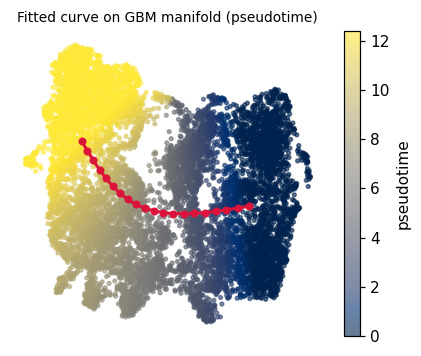

In [12]:
# visual inspection — fitted curve edges drawn over the cloud (guards against an unseen fold)
F = np.asarray(adata.uns['graph']['F']); Bc = np.asarray(adata.uns['graph']['B'])
ii, jj = np.where(np.triu(Bc>0))
fig, ax = plt.subplots(figsize=(4.6, 3.6))
sca = ax.scatter(adata.obsm['X_umap'][:,0], adata.obsm['X_umap'][:,1], c=t, cmap='cividis', s=6, alpha=.6)
for a, b in zip(ii, jj):
    ax.plot([F[0,a],F[0,b]], [F[1,a],F[1,b]], '-', color='crimson', lw=2, zorder=5)
ax.scatter(F[0], F[1], c='crimson', s=18, zorder=6)
ax.axis('off'); ax.set_title('Fitted curve on GBM manifold (pseudotime)', size=9)
plt.colorbar(sca, ax=ax, label='pseudotime'); plt.show()

saved manifold.h5ad + manifold.pdf


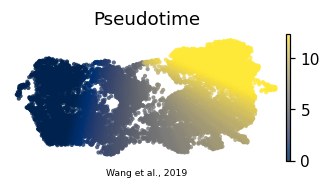

In [13]:
# save manifold + manifold.pdf (house (3.5,1.5) strip, pseudotime-coloured, external colorbar)
adata.uns['epg'] = {'NodePositions': np.asarray(adata.uns['epg']['NodePositions'])}
adata.write(os.path.join(pth_out, 'manifold.h5ad'))
xl = adata.obsm['X_umap_lin']
xlo, xhi = np.percentile(xl[:,0], [0.3,99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3,99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='t', cmap='cividis', size=30, alpha=.8, colorbar_loc='right',
           frameon=False, show=False, ax=ax, title='Pseudotime')
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.text(.5, -.12, 'Wang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'manifold.pdf'), bbox_inches='tight'); plt.show()
print('saved manifold.h5ad + manifold.pdf')